In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

project_path = "/content/drive/MyDrive/DL projects"

print(os.listdir(project_path))


['NEU-CLS.rar', 'dataset']


In [3]:
# Install extraction utility
!apt-get -qq install -y unrar

# Define paths
project_path = "/content/drive/MyDrive/DL projects"
extract_path = project_path + "/dataset"

# Create folder
os.makedirs(extract_path, exist_ok=True)

# Extract dataset
!unrar x -o+ "/content/drive/MyDrive/DL projects/NEU-CLS.rar" "/content/drive/MyDrive/DL projects/dataset/"

# Verify extraction
data_path = extract_path + "/NEU-CLS"

images = [f for f in os.listdir(data_path) if f.lower().endswith(".bmp")]

print("Total images:", len(images))


UNRAR 7.00 freeware      Copyright (c) 1993-2024 Alexander Roshal


Extracting from /content/drive/MyDrive/DL projects/NEU-CLS.rar

Extracting  /content/drive/MyDrive/DL projects/dataset/NEU-CLS/Cr_1.bmp       0%  OK 
Extracting  /content/drive/MyDrive/DL projects/dataset/NEU-CLS/Cr_10.bmp       0%  OK 
Extracting  /content/drive/MyDrive/DL projects/dataset/NEU-CLS/Cr_100.bmp       0%  OK 
Extracting  /content/drive/MyDrive/DL projects/dataset/NEU-CLS/Cr_101.bmp       0%  OK 
Extracting  /content/drive/MyDrive/DL projects/dataset/NEU-CLS/Cr_102.bmp       0%  OK 
Extracting  /content/drive/MyDrive/DL projects/dataset/NEU-CLS/Cr_103.bmp       0%  OK 
Extracting  /content/drive/MyDrive/DL projects/dataset/NEU-CLS/Cr_104.bmp       0%  OK 
Extracting  /content/drive/MyDrive/DL projects/dataset/NEU-CLS/Cr_105.bmp       0%  OK 
Extracting  /content/drive/MyDrive/DL projects/dataset/NEU-CLS/Cr_106.bmp       0%  O

In [4]:
from collections import Counter

# Dataset location
data_path = "/content/drive/MyDrive/DL projects/dataset/NEU-CLS"

# Get image filenames
files = sorted([
    f for f in os.listdir(data_path)
    if f.lower().endswith(".bmp")
])

# Map defect categories to numbers
class_map = {
    "Cr": 0,
    "In": 1,
    "Pa": 2,
    "PS": 3,
    "RS": 4,
    "Sc": 5
}

# Generate numerical labels
labels = []

for filename in files:
    category = filename.split("_")[0]
    labels.append(class_map[category])

# Display dataset information
print("Total images:", len(files))
print("Number of classes:", len(class_map))
print("Class distribution:", Counter(f.split("_")[0] for f in files))
print("First 10 labels:", labels[:10])

Total images: 1800
Number of classes: 6
Class distribution: Counter({'Cr': 300, 'In': 300, 'PS': 300, 'Pa': 300, 'RS': 300, 'Sc': 300})
First 10 labels: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [5]:
from sklearn.model_selection import train_test_split

# First split: 70% training, 30% remaining
X_train, X_temp, y_train, y_temp = train_test_split(
    files,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

# Second split: Divide remaining 30% equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Display split sizes
print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))
print("Total images:", len(X_train) + len(X_val) + len(X_test))

Training images: 1260
Validation images: 270
Testing images: 270
Total images: 1800


In [6]:
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms

# Image preprocessing
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

# Custom dataset class
class SteelDefectDataset(Dataset):

    def __init__(self, filenames, labels, data_path, transform=None):
        self.filenames = filenames
        self.labels = labels
        self.data_path = data_path
        self.transform = transform

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, index):
        image_path = os.path.join(self.data_path, self.filenames[index])

        image = Image.open(image_path).convert("L")
        label = self.labels[index]

        if self.transform:
            image = self.transform(image)

        return image, label

In [7]:
train_dataset = SteelDefectDataset(
    X_train, y_train, data_path, transform
)

val_dataset = SteelDefectDataset(
    X_val, y_val, data_path, transform
)

test_dataset = SteelDefectDataset(
    X_test, y_test, data_path, transform
)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

Training: 1260
Validation: 270
Testing: 270


In [8]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

print("DataLoaders created successfully!")

DataLoaders created successfully!


In [9]:
images, labels_batch = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels_batch.shape)

Image batch shape: torch.Size([32, 1, 128, 128])
Label batch shape: torch.Size([32])


In [14]:
# 1. Imports
import torch
import torch.nn as nn
import torch.optim as optim

# 2. Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 3. Define CNN
class SteelCNN(nn.Module):

    def __init__(self):
        super(SteelCNN, self).__init__()

        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2)

        self.fc1 = nn.Linear(64 * 16 * 16, 128)
        self.fc2 = nn.Linear(128, 6)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.pool(self.relu(self.conv3(x)))

        x = torch.flatten(x, 1)

        x = self.relu(self.fc1(x))
        x = self.fc2(x)

        return x

# 4. Create model
model = SteelCNN().to(device)

print("Device:", device)
print(model)

Device: cpu
SteelCNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=16384, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=6, bias=True)
)


In [15]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function and optimizer configured!")

Loss function and optimizer configured!


In [20]:
num_epochs = 10

for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels_batch in train_loader:
      images = images.to(device)
      labels_batch = labels_batch.to(device)

      optimizer.zero_grad()

      outputs = model(images)

      loss = criterion(outputs, labels_batch)

      loss.backward()

      optimizer.step()

      running_loss += loss.item()

      _, predicted = torch.max(outputs.data, 1)

      total += labels_batch.size(0)
      correct += (predicted == labels_batch).sum().item()

    epoch_loss = running_loss / len(train_loader)

    epoch_accuracy = 100 * correct / total

    print(f"Epoch [{epoch+1}/{num_epochs}], "
          f"Loss: {epoch_loss:.4f}, "
          f"Accuracy: {epoch_accuracy:.2f}%")

    model.eval()

    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels_batch in val_loader:

            images = images.to(device)
            labels_batch = labels_batch.to(device)

            outputs = model(images)

            _, predicted = torch.max(outputs.data, 1)

            val_total += labels_batch.size(0)
            val_correct += (predicted == labels_batch).sum().item()

    val_accuracy = 100 * val_correct / val_total

    print(f"Validation Accuracy: {val_accuracy:.2f}%")

Epoch [1/10], Loss: 1.0081, Accuracy: 64.37%
Validation Accuracy: 73.70%
Epoch [2/10], Loss: 0.6739, Accuracy: 77.62%
Validation Accuracy: 83.70%
Epoch [3/10], Loss: 0.3923, Accuracy: 86.98%
Validation Accuracy: 82.96%
Epoch [4/10], Loss: 0.3312, Accuracy: 88.33%
Validation Accuracy: 88.52%
Epoch [5/10], Loss: 0.2464, Accuracy: 91.03%
Validation Accuracy: 90.00%
Epoch [6/10], Loss: 0.1880, Accuracy: 94.52%
Validation Accuracy: 90.37%
Epoch [7/10], Loss: 0.1764, Accuracy: 94.37%
Validation Accuracy: 91.48%
Epoch [8/10], Loss: 0.1830, Accuracy: 93.89%
Validation Accuracy: 88.89%
Epoch [9/10], Loss: 0.2201, Accuracy: 93.49%
Validation Accuracy: 91.48%
Epoch [10/10], Loss: 0.1422, Accuracy: 95.87%
Validation Accuracy: 94.07%


In [21]:
model_save_path = "/content/drive/MyDrive/DL projects/steel_defect_cnn.pth"

torch.save(model.state_dict(), model_save_path)

print("Model saved successfully!")

Model saved successfully!


In [22]:
model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels_batch in test_loader:

        images = images.to(device)
        labels_batch = labels_batch.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs.data, 1)

        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels_batch.cpu().numpy())

print("Testing completed!")

Testing completed!


In [23]:
from sklearn.metrics import accuracy_score

test_accuracy = accuracy_score(all_labels, all_predictions)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Accuracy: 95.19%


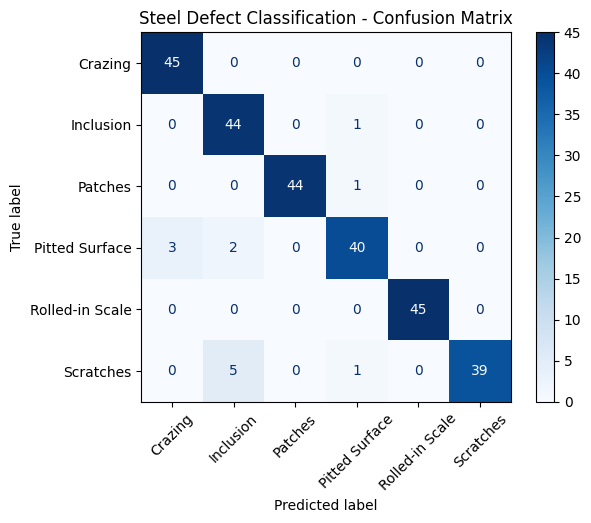

In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(all_labels, all_predictions)

class_names = [
    "Crazing",
    "Inclusion",
    "Patches",
    "Pitted Surface",
    "Rolled-in Scale",
    "Scratches"
]

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Steel Defect Classification - Confusion Matrix")
plt.show()

In [25]:
from sklearn.metrics import classification_report

report = classification_report(
    all_labels,
    all_predictions,
    target_names=class_names
)

print(report)

                 precision    recall  f1-score   support

        Crazing       0.94      1.00      0.97        45
      Inclusion       0.86      0.98      0.92        45
        Patches       1.00      0.98      0.99        45
 Pitted Surface       0.93      0.89      0.91        45
Rolled-in Scale       1.00      1.00      1.00        45
      Scratches       1.00      0.87      0.93        45

       accuracy                           0.95       270
      macro avg       0.96      0.95      0.95       270
   weighted avg       0.96      0.95      0.95       270



In [26]:
model_save_path = "/content/drive/MyDrive/DL projects/steel_defect_cnn.pth"

torch.save(model.state_dict(), model_save_path)

print("Model saved successfully!")

Model saved successfully!
